# Bordeaux_Wines

In [1]:
# step 1:import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# step 2:Load the dataset
df = pd.read_csv(r"C:\Users\asusvivobook\Desktop\FSDS\ML Practicals\Navie Bayes\Wine_Detection\BordeauxWines.csv")

In [3]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Name', 'Year', 'Score', 'Price', 'BLOOD ORANGE', 'CITRUS', 'CITRUS PEEL', 'CITRUS ZEST', 'CLEMENTINE', 'LIME', 'GRAPEFRUIT', 'GRAPEFRUIT PEEL', 'ORANGE', 'KEY LIME', 'LEMON', 'LEMON MOUSSE', 'LEMON PEEL', 'LEMON SEED', 'LEMON ZEST', 'LEMON-LIME', 'LIME PEEL', 'MARMALADE', 'ORANGE CREAM', 'ORANGE PEEL', 'ORANGE ZEST', 'RED GRAPEFRUIT', 'TANGERINE', 'ACAI BERRY', 'BERRY', 'BILBERRY', 'BLACK CURRANT', 'BLACK CURRANT CONFITURE', 'BLACK RASPBERRY', 'BLACKBERRY', 'BLACKBERRY CONFITURE', 'BLUEBERRY', 'BLUEBERRY CREAM', 'BOYSENBERRY', 'BRAMBLEBERRY', 'CRANBERRY', 'RASPBERRY', 'CURRANT', 'DARK BERRY', 'DARK BLUEBERRY', 'DARK CURRANT', 'HUCKLEBERRY', 'GOOSEBERRY', 'LOGANBERRY', 'MULBERRY', 'OLALLIEBERRY', 'RASPBERRY TART', 'RED BERRY', 'RED CURRANT', 'STRAWBERRY', 'WHITE CURRANT', 'BLACK FRUIT', 'BLUE FRUITS', 'DARK FRUIT', 'EXOTIC FRUIT', 'FRUIT', 'RED FRUIT', 'SWEET FRUIT', 'TROPICAL FRUIT', 'WHITE FRUIT', 'APPLE', 'APPLE PIE', 'APPLE TART', 'APPLE TARTE TATIN', 'APRICOT', 'BA

In [4]:
print("\nData types:")
print(df.dtypes)


Data types:
Name               str
Year             int64
Score            int64
Price              str
BLOOD ORANGE     int64
                 ...  
ETHYL ACETATE    int64
ALCOHOL          int64
FROTH            int64
MENTHOL          int64
SHERRY           int64
Length: 989, dtype: object


In [5]:
# Step 4: Check Score column

print("\nScore information:")
print(df["Score"].head(20))

print("\nScore data type:")
print(df["Score"].dtype)

print("\nMissing values in Score:")
print(df["Score"].isnull().sum())

print("\nScore statistics:")
print(df["Score"].describe())


Score information:
0     84
1     84
2     84
3     84
4     84
5     84
6     84
7     84
8     84
9     84
10    83
11    83
12    83
13    83
14    80
15    79
16    78
17    84
18    84
19    84
Name: Score, dtype: int64

Score data type:
int64

Missing values in Score:
0

Score statistics:
count    14349.000000
mean        87.793714
std          3.468579
min         60.000000
25%         86.000000
50%         88.000000
75%         90.000000
max        100.000000
Name: Score, dtype: float64


In [6]:
# Step 5: Create classification target

# Remove rows where Score is missing
df = df.dropna(subset=["Score"])

# Create target column
df["Target"] = df["Score"].apply(
    lambda x: "Good" if x >= 90 else "Average"
)

print("\nTarget distribution:")
print(df["Target"].value_counts())


Target distribution:
Target
Average    10086
Good        4263
Name: count, dtype: int64


C:\Users\asusvivobook\AppData\Local\Temp\ipykernel_12316\1523101470.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["Target"] = df["Score"].apply(


In [7]:
# Step 6: Check missing values

missing_values = df.isnull().sum()

print("\nColumns with missing values:")
print(missing_values[missing_values > 0])


Columns with missing values:
Series([], dtype: int64)


In [8]:
# Step 7: Select features and target

# Remove unnecessary columns
X = df.drop(["Name", "Score", "Target"], axis=1)

# Target variable
y = df["Target"]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(y.value_counts())


Features shape: (14349, 987)
Target shape: (14349,)

Target classes:
Target
Average    10086
Good        4263
Name: count, dtype: int64


In [9]:
# Step 8: Check non-numeric columns

print("\nNon-numeric columns:")
print(X.select_dtypes(include=["object"]).columns.tolist())


Non-numeric columns:
['Price']


C:\Users\asusvivobook\AppData\Local\Temp\ipykernel_12316\2312973566.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(X.select_dtypes(include=["object"]).columns.tolist())


In [10]:
# Step 9: Convert features to numeric

# Convert all columns to numeric
X = X.apply(pd.to_numeric, errors="coerce")

print("\nData types after conversion:")
print(X.dtypes.value_counts())

print("\nMissing values after conversion:")
print(X.isnull().sum().sum())


Data types after conversion:
int64      986
float64      1
Name: count, dtype: int64

Missing values after conversion:
14349


In [11]:
# Step 10: Handle missing values

X = X.fillna(X.median(numeric_only=True))

print("\nTotal missing values after filling:")
print(X.isnull().sum().sum())


Total missing values after filling:
14349


In [12]:
# Step 11: Final feature check

print("\nFinal X shape:", X.shape)
print("Final y shape:", y.shape)

print("\nFirst 5 rows of X:")
print(X.head())

print("\nTarget values:")
print(y.head())


Final X shape: (14349, 987)
Final y shape: (14349,)

First 5 rows of X:
   Year  Price  BLOOD ORANGE  CITRUS  CITRUS PEEL  CITRUS ZEST  CLEMENTINE  \
0  2008    NaN             0       0            0            0           0   
1  2008    NaN             0       0            0            0           0   
2  2008    NaN             0       0            0            0           0   
3  2008    NaN             0       0            0            0           0   
4  2008    NaN             0       0            0            0           0   

   LIME  GRAPEFRUIT  GRAPEFRUIT PEEL  ...  SKUNK  SULFUR DIOXIDE  \
0     0           0                0  ...      0               0   
1     0           0                0  ...      0               0   
2     0           0                0  ...      0               0   
3     0           0                0  ...      0               0   
4     0           0                0  ...      0               0   

   WET WOOL,WET DOG  ACETIC ACID  ETHANOL  ETHYL 

In [13]:
# Step 12: Split the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting data:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)


Training data:
X_train: (11479, 987)
y_train: (11479,)

Testing data:
X_test: (2870, 987)
y_test: (2870,)


In [14]:
# Step 13: Feature scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nFeature scaling completed!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
c:\Users\asusvivobook\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count



Feature scaling completed!
X_train shape: (11479, 987)
X_test shape: (2870, 987)


In [16]:
# Step 14A: Check training data

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nX_train data type:")
print(type(X_train))

print("\ny_train data type:")
print(type(y_train))

print("\nMissing values in X_train:")
print(pd.DataFrame(X_train).isnull().sum().sum())

print("\nTarget classes:")
print(y_train.value_counts())

X_train shape: (11479, 987)
y_train shape: (11479,)

X_train data type:
<class 'numpy.ndarray'>

y_train data type:
<class 'pandas.Series'>

Missing values in X_train:
11479

Target classes:
Target
Average    8069
Good       3410
Name: count, dtype: int64


In [18]:
# Step 9: Select features and target

X = df.drop(["Name", "Score", "Target"], axis=1)
y = df["Target"]

# Convert all features to numeric
X = X.apply(pd.to_numeric, errors="coerce")

# Remove columns that are completely empty
X = X.dropna(axis=1, how="all")

# Fill remaining missing values with median
X = X.fillna(X.median())

print("X shape:", X.shape)
print("Total missing values:", X.isnull().sum().sum())


# Step 10: Train-test split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


# Step 11: Feature scaling

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Scaling completed!")


# Step 12: Train Naive Bayes

from sklearn.naive_bayes import GaussianNB

model = GaussianNB()

model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")

X shape: (14349, 986)
Total missing values: 0
X_train: (11479, 986)
X_test: (2870, 986)
Scaling completed!
Naive Bayes model trained successfully!


In [19]:
# Step 15: Make predictions

y_pred = model.predict(X_test)

print("\nPredictions made successfully!")

print("\nFirst 20 predictions:")
print(y_pred[:20])


Predictions made successfully!

First 20 predictions:
['Average' 'Average' 'Average' 'Average' 'Average' 'Average' 'Average'
 'Average' 'Average' 'Average' 'Average' 'Average' 'Average' 'Good'
 'Average' 'Average' 'Average' 'Average' 'Average' 'Average']


In [20]:
# Step 16: Calculate accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")


Accuracy: 0.7571428571428571
Accuracy Percentage: 75.71428571428571 %


In [21]:
# Step 17: Classification report

from sklearn.metrics import classification_report

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

     Average       0.75      0.97      0.85      2017
        Good       0.79      0.25      0.38       853

    accuracy                           0.76      2870
   macro avg       0.77      0.61      0.61      2870
weighted avg       0.76      0.76      0.71      2870



In [22]:
# Step 18: Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[1960   57]
 [ 640  213]]


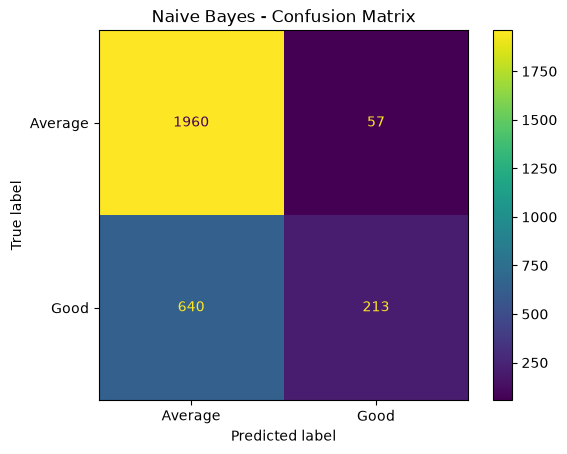

In [23]:
# Display confusion matrix with class names

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()

plt.title("Naive Bayes - Confusion Matrix")
plt.show()

In [ ]:
# Step 19: Save the model and scaler

import joblib

joblib.dump(model, "naive_bayes_model.pkl")
joblib.dump(scaler, "naive_bayes_scaler.pkl")

print("\nModel saved successfully!")
print("Scaler saved successfully!")


Model saved successfully!
Scaler saved successfully!


In [25]:
# Step 20: Save processed dataset

df.to_csv("BordeauxWines_processed.csv", index=False)

print("\nProcessed dataset saved successfully!")


Processed dataset saved successfully!
